# Image Classification with CNNs on a CPU Budget
Experiments for the diploma thesis (University of Lodz).
**Research question:** how do architecture depth, kernel size/stride and transfer learning affect accuracy and training cost on a CPU?

**Datasets:** Fashion-MNIST; CIFAR-10 (fixed 10,000-image training subset).
**Models:** baseline CNN, deeper CNN (batch norm + dropout), frozen MobileNetV3-small (only the final layer trained).
**Hardware:** Google Colab CPU runtime (Intel(R) Xeon(R) CPU @ 2.20GHz, 1, 12.27GB RAM).
**Run order:** run cells top to bottom. Results are logged to Google Drive, so finished runs are skipped after a disconnect.

In [ ]:
!lscpu

Architecture:                x86_64
  CPU op-mode(s):            32-bit, 64-bit
  Address sizes:             46 bits physical, 48 bits virtual
  Byte Order:                Little Endian
CPU(s):                      2
  On-line CPU(s) list:       0,1
Vendor ID:                   GenuineIntel
  Model name:                Intel(R) Xeon(R) CPU @ 2.20GHz
    CPU family:              6
    Model:                   79
    Thread(s) per core:      2
    Core(s) per socket:      1
    Socket(s):               1
    Stepping:                0
    BogoMIPS:                4400.42
    Flags:                   fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pg
                             e mca cmov pat pse36 clflush mmx fxsr sse sse2 ss h
                             t syscall nx pdpe1gb rdtscp lm constant_tsc rep_goo
                             d nopl xtopology nonstop_tsc cpuid tsc_known_freq p
                             ni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2ap
                   

In [ ]:
!free -h

               total        used        free      shared  buff/cache   available
Mem:            12Gi       2.8Gi       5.9Gi       2.6Mi       4.3Gi       9.9Gi
Swap:             0B          0B          0B


In [ ]:
from google.colab import drive
import csv, os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, models
import glob

## 1. Setup and logging
Mounts Google Drive and defines the logging helpers. Every finished run appends one row to `results.csv` (test accuracy, training time, trainable parameters) and its per-epoch metrics to `curves.csv`. `already_done` lets the experiment cells skip completed runs. All outputs go to `thesis_results/` on Drive.


In [ ]:
drive.mount('/content/drive')
# Pass the local paths if the notebook is running locally
LOG_DIR = '/content/drive/MyDrive/thesis_results'
DATA_DIR = '/content/drive/MyDrive/thesis_data'
FIG_DIR = f'{LOG_DIR}/figures'
PRED_DIR = f'{LOG_DIR}/preds'
GRAPHS_DIR = f'{LOG_DIR}/graphs'

SIZE = 96

FASHION_CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
                   'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
CIFAR_CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
                 'dog', 'frog', 'horse', 'ship', 'truck']

MAIN = ['baseline', 'deeper', 'mobilenet_frozen']

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(PRED_DIR, exist_ok=True)
os.makedirs(GRAPHS_DIR, exist_ok=True)

RESULTS, CURVES = f'{LOG_DIR}/results.csv', f'{LOG_DIR}/curves.csv'

torch.set_num_threads(os.cpu_count())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
def already_done(ds,model, seed):
  if not os.path.exists(RESULTS):
    return False
  with open(RESULTS) as f:
    return any((r['dataset'], r['model'], r['seed']) == (ds, model, str(seed)) for r in csv.DictReader(f))

def log_run(path, rows):
    new = not os.path.exists(path)
    with open(path, 'a', newline='') as f:
      w = csv.DictWriter(f, fieldnames=rows[0])
      if new:
        w.writeheader()
      w.writerows(rows)

def set_seed(s):
  random.seed(s); np.random.seed(s); torch.manual_seed(s)



## 2. Data
Loads Fashion-MNIST and CIFAR-10 from Drive (downloaded once). The CIFAR-10 training set is reduced to a fixed random subset of 10,000 images (selection seed 0) so that every model and seed uses identical data. 10% of the training data is held out for validation; the official test set is used only for the final evaluation.
`normalise` standardises each channel with **training-set** mean and standard deviation (no leakage from validation or test data).


In [ ]:
def load_data(name):
  if name =='fashion':
    tr = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
    te = datasets.FashionMNIST(DATA_DIR, train=False, download=True)
    X,y = tr.data.unsqueeze(1).float()/255, tr.targets
    X_t, y_t = te.data.unsqueeze(1).float() / 255, te.targets
    n_use = len(X)

  else:
      tr = datasets.CIFAR10(DATA_DIR, train=True, download=True)
      te = datasets.CIFAR10(DATA_DIR, train=False, download=True)

      X = torch.tensor(tr.data).permute(0,3,1,2).float() /255
      y = torch.tensor(tr.targets)

      X_t = torch.tensor(te.data).permute(0,3,1,2).float() / 255
      y_t = torch.tensor(te.targets)

      n_use = 10000

  idx = torch.from_numpy(np.random.RandomState(0).permutation(len(X))[:n_use])

  X,y = X[idx], y[idx]

  nv = len(X) // 10
  return dict(X_tr=X[nv:], y_tr=y[nv:], X_va=X[:nv], y_va=y[:nv], X_te=X_t, y_te=y_t)


def normalise(d):
  m = d['X_tr'].mean((0,2,3), keepdim=True)
  s = d['X_tr'].std((0,2,3), keepdim=True)
  return {k: ((v-m)/s if k.startswith('X') else v) for k,v in d.items()}

#Preprocessing
Randomly selected test images (fixed seed) at each step: original, standardised for the CNNs, and resized/normalised for MobileNet. Normalised rows are rescaled to 0-1 for display only; the pixel ranges below each image show the real values.


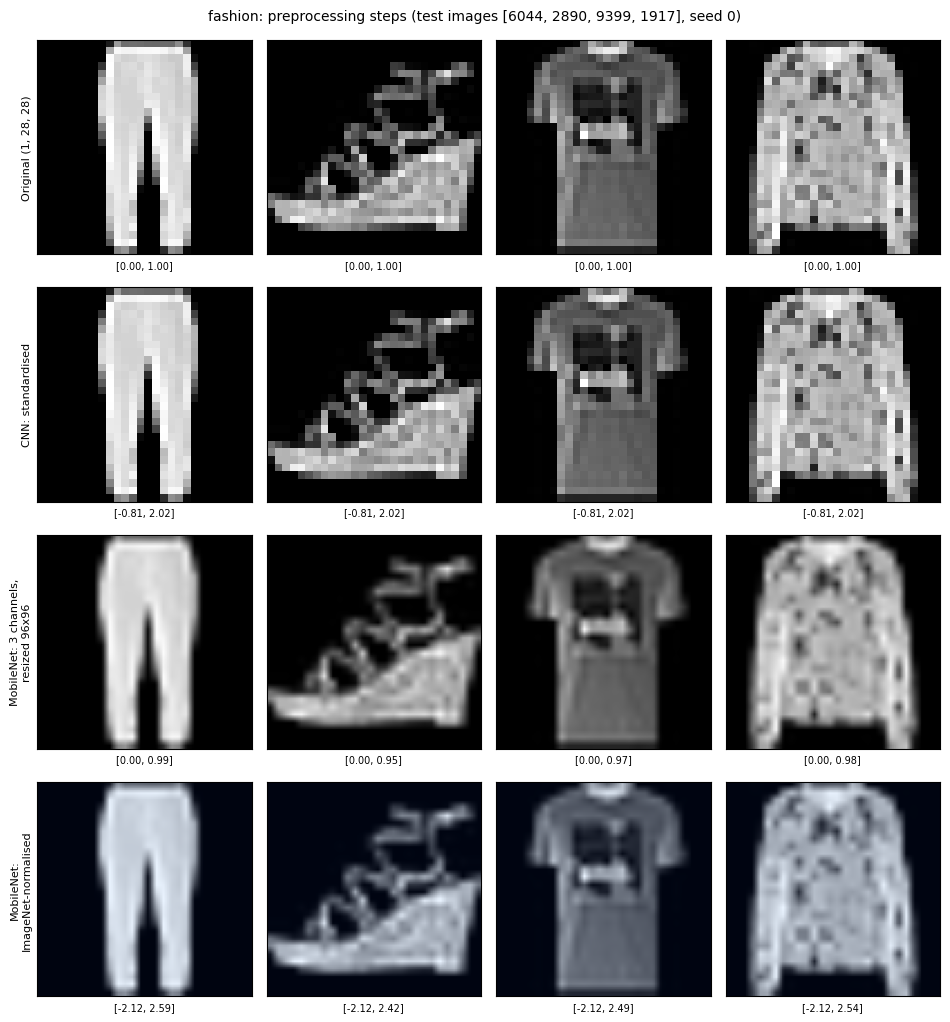

100%|██████████| 170M/170M [17:56<00:00, 158kB/s]


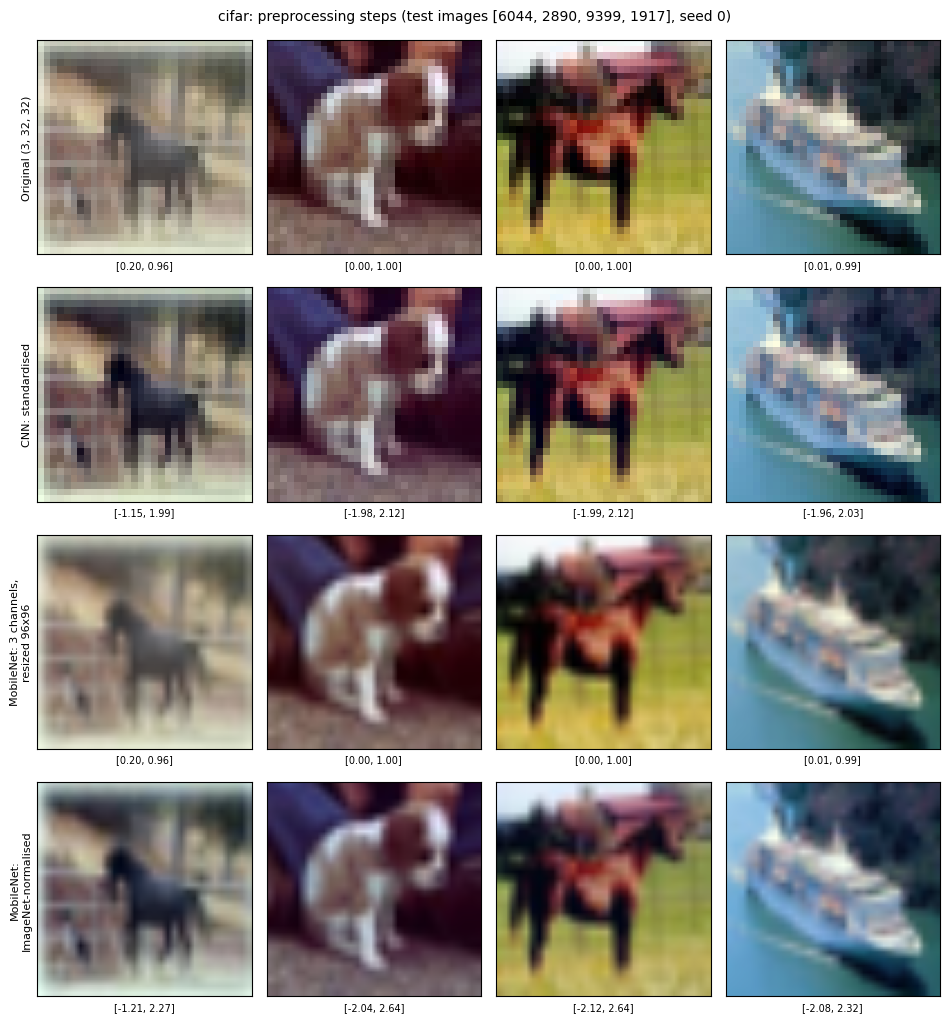

In [ ]:
def save_fig(name):
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=300, bbox_inches='tight')
    plt.savefig(f'{FIG_DIR}/{name}.pdf', bbox_inches='tight')

def to_show(t, rescale):
    t = t.clone()
    if rescale:   # normalised values leave [0, 1]; rescale for display only
        t = (t - t.min()) / (t.max() - t.min() + 1e-8)
    return t.clamp(0, 1).permute(1, 2, 0).squeeze().numpy()

def preprocessing_figure(raw, ds, n=4, seed=0):
    # random but reproducible test images
    g = torch.Generator().manual_seed(seed)
    idxs = torch.randperm(len(raw['X_te']), generator=g)[:n].tolist()

    d = normalise(raw)
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    X = raw['X_te'][idxs]                        # original, values in [0, 1]
    Xc = d['X_te'][idxs]                         # CNN input (standardised)
    Xm = X.repeat(1, 3, 1, 1) if X.shape[1] == 1 else X
    Xm = F.interpolate(Xm, size=SIZE, mode='bilinear', align_corners=False)
    Xmn = (Xm - mean) / std                      # what MobileNet receives

    rows = [(f'Original {tuple(X.shape[1:])}', X, False),
            ('CNN: standardised', Xc, True),
            (f'MobileNet: 3 channels,\nresized {SIZE}x{SIZE}', Xm, False),
            ('MobileNet:\nImageNet-normalised', Xmn, True)]

    fig, ax = plt.subplots(len(rows), n, figsize=(2.4 * n, 2.6 * len(rows)), squeeze=False)
    for r, (title, T, rescale) in enumerate(rows):
        for c in range(n):
            ax[r, c].imshow(to_show(T[c], rescale), cmap='gray')
            ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
            ax[r, c].set_xlabel(f'[{T[c].min():.2f}, {T[c].max():.2f}]', fontsize=7)
        ax[r, 0].set_ylabel(title, fontsize=8)
    fig.suptitle(f'{ds}: preprocessing steps (test images {idxs}, seed {seed})', fontsize=10)
    plt.tight_layout()
    save_fig(f'fig_preprocessing_{ds}')
    plt.show()

preprocessing_figure(load_data('fashion'), 'fashion', n=4, seed=0)
preprocessing_figure(load_data('cifar'), 'cifar', n=4, seed=0)

## 3. Models
- **Baseline CNN:** two convolution layers (16 and 32 filters), ReLU, max pooling, small classifier head. Kernel size `k` and stride `s` are parameters (used in the ablation). Adaptive average pooling keeps the head size fixed.
- **Deeper CNN:** three blocks of two convolutions with batch normalisation, ReLU, max pooling and dropout (0.25).
- **Frozen MobileNetV3-small:** pretrained ImageNet backbone, images resized to [96]x[96] with grey channels repeated to 3 and ImageNet normalisation. Features are extracted once and cached; only a final linear layer is trained.

In [ ]:
def baseline(in_ch, k=3, s=1):
  p = k//2

  return nn.Sequential(
      nn.Conv2d(in_ch, 16,k,s,p), nn.ReLU(), nn.MaxPool2d(2),
      nn.Conv2d(16, 32, k, s, p), nn.ReLU(), nn.MaxPool2d(2),
      nn.AdaptiveAvgPool2d(4), nn.Flatten(),
      nn.Linear(32*16, 64), nn.ReLU(), nn.Linear(64,10))


def block(i,o):
  return [nn.Conv2d(i,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(),
  nn.Conv2d(o,o,3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
          nn.MaxPool2d(2), nn.Dropout(0.25)]

def deeper(in_ch):
  return nn.Sequential(*block(in_ch, 16), *block(16,32), *block(32,64), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64,10))

In [ ]:
def mobilenet_feat(d):
  net = models.mobilenet_v3_small(
      weights=models.MobileNet_V3_Small_Weights.DEFAULT).eval()
  body = nn.Sequential(net.features, net.avgpool, nn.Flatten(), *list(net.classifier)[:3])

  mean = torch.tensor([0.485,0.456,0.406]).view(1,3,1,1)
  std = torch.tensor([0.229,0.224,0.225]).view(1,3,1,1)

  def extract(X):
    out = []
    with torch.no_grad():
      for i in range(0, len(X), 256):
        b = X[i:i+256]
        if b.shape [1] == 1:
          b = b.repeat(1,3,1,1)
        b = F.interpolate(b, size=SIZE, mode='bilinear',align_corners=False)
        out.append(body((b-mean)/std))
    return torch.cat(out)

  t_0 = time.time()
  f = {k: (extract(v) if k.startswith('X') else v) for k,v in d.items()}
  return f, time.time() - t_0

def cached_features(raw, ds):
    path = f'{DATA_DIR}/feats_{ds}_mnv3s_{SIZE}.pt'
    if os.path.exists(path):
        return torch.load(path)          # (features dict, extraction time)
    feats, t = mobilenet_feat(raw)
    torch.save((feats, t), path)
    return feats, t

# 4. Training and evaluation
`train_run` trains one model for one seed with Adam (lr [1e-3], batch size [128]) and a fixed number of epochs. It records the **training time** (training only, plus one-off feature extraction for MobileNet), per-epoch loss and validation accuracy, test accuracy, a confusion matrix and the test predictions.

In [ ]:
def evaluate(model, X, y):
  model.eval(); preds = []
  with torch.no_grad():
    for i in range(0,len(X), 1000):
      preds.append(model(X[i:i+1000]).argmax(1))
  preds = torch.cat(preds)
  return (preds == y).float().mean().item(), preds

In [ ]:
def val_loss(model, X, y):
    model.eval(); tot = 0.0
    with torch.no_grad():
        for i in range(0, len(X), 1000):
            tot += F.cross_entropy(model(X[i:i + 1000]), y[i:i + 1000],
                                   reduction='sum').item()
    return tot / len(X)

In [ ]:
def train_run(make_model, ds, d, name, seed ,epochs, extra_time=0.0, bs=128, lr=1e-3):
  if already_done(ds, name, seed): return
  set_seed(seed)
  model = make_model()
  opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
  n, train_t, curve = len(d['X_tr']), 0.0, []
  for ep in range(epochs):
    model.train(); t_0 = time.time(); perm = torch.randperm(n); tot = 0.0

    for i in range(0,n,bs):
      j = perm[i:i+bs]
      loss = F.cross_entropy(model(d['X_tr'][j]), d['y_tr'][j])

      opt.zero_grad(); loss.backward(); opt.step()
      tot += loss.item()* len(j)

    train_t += time.time() - t_0
    va, _ = evaluate(model, d['X_va'], d['y_va'])
    vl = val_loss(model, d['X_va'], d['y_va'])
    curve.append(dict(dataset=ds, model=name, seed=seed, epoch=ep + 1, train_loss=tot / n, val_acc=va, vald_loss=vl))

  te, preds = evaluate(model, d['X_te'], d['y_te'])
  cm = torch.bincount(d['y_te']*10 + preds, minlength=100).view(10,10)
  np.save(f'{LOG_DIR}/cm_{ds}_{name}_seed{seed}.npy', cm.numpy())
  log_run(CURVES, curve)
  log_run(RESULTS, [dict(dataset=ds, model=name, seed=seed, test_acc=te, train_time_s=train_t + extra_time, params=sum(p.numel() for p in model.parameters() if p.requires_grad))])

#Main experiments
Three models x [5] seeds on Fashion-MNIST and x [3] seeds on the CIFAR-10 subset. Epochs: Fashion-MNIST [..], CIFAR-10 [..], chosen from validation curves of a pilot run. Results accumulate in `results.csv`.


In [ ]:
EPOCHS = {'fashion': 10, 'cifar':15}
for ds in ['fashion', 'cifar']:
  raw = load_data(ds); d = normalise(raw); c = d['X_tr'].shape[1]

  seeds = range(5) if ds == 'fashion' else range(3)
  for s in seeds:
    train_run(lambda: baseline(c), d=d, ds=ds, name='baseline', seed=s, epochs=EPOCHS[ds])
    train_run(lambda: deeper(c), d=d, ds=ds, name='deeper', seed=s, epochs=EPOCHS[ds])

  feats, t_ext = cached_features(raw, ds)
  for s in seeds:
    train_run(lambda: nn.Linear(1024, 10), d=feats, ds=ds, name='mobilenet_frozen', seed=s, epochs=EPOCHS[ds], extra_time=t_ext)

#Kernel size and stride ablation
Mean test accuracy and training time for each kernel/stride combination (Fashion-MNIST, baseline CNN).

In [ ]:
d = normalise(load_data('fashion'))
for k in [3, 5, 7]:
    for st in [1, 2]:
        name = 'baseline' if (k, st) == (3, 1) else f'baseline_k{k}_s{st}'
        for seed in range(3):
            train_run(lambda: baseline(1, k, st),
                      d=d, ds='fashion', name=name,
                      seed=seed, epochs=EPOCHS['fashion'])

In [ ]:
df = pd.read_csv(RESULTS)
df.groupby(['dataset', 'model'])[['test_acc', 'train_time_s']].agg(['mean', 'std'])

test_acc           train_time_s           
                              mean       std         mean        std
dataset model                                                       
cifar   baseline          0.580267  0.016033    85.178865   1.908504
        deeper            0.645333  0.008075   313.889733   5.058240
        mobilenet_frozen  0.769300  0.000819    46.479462   0.049070
fashion baseline          0.882840  0.002756   276.392968   3.316484
        baseline_k3_s2    0.885667  0.004535   108.851355   3.362457
        baseline_k5_s1    0.892333  0.011930   392.462543   3.759765
        baseline_k5_s2    0.894467  0.004788   125.606394   1.679405
        baseline_k7_s1    0.899400  0.005703   545.365164  14.704484
        baseline_k7_s2    0.898067  0.002303   148.195104   6.280989
        deeper            0.912980  0.011417   982.377894  19.634247
        mobilenet_frozen  0.879520  0.001346   169.887530   2.004701

In [ ]:
EPOCHS = {'fashion': 10, 'cifar':15}
def rerun_for_preds(make_model, d, ds, name, seed, epochs, bs=128, lr=1e-3):
    set_seed(seed)
    model = make_model()
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    n = len(d['X_tr'])
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n)
        for i in range(0, n, bs):
            j = perm[i:i + bs]
            loss = F.cross_entropy(model(d['X_tr'][j]), d['y_tr'][j])
            opt.zero_grad(); loss.backward(); opt.step()
    te, preds = evaluate(model, d['X_te'], d['y_te'])
    cm = torch.bincount(d['y_te'] * 10 + preds, minlength=100).view(10, 10).numpy()
    old = np.load(f'{LOG_DIR}/cm_{ds}_{name}_seed{seed}.npy')
    print(ds, name, 'test acc', round(te, 4), '| same confusion matrix as logged run:', np.array_equal(cm, old))
    np.save(f'{LOG_DIR}/preds_{ds}_{name}_seed{seed}.npy', preds.numpy())

for ds in ['fashion', 'cifar']:
    raw = load_data(ds); d = normalise(raw); c = d['X_tr'].shape[1]
    ep = EPOCHS[ds]
    rerun_for_preds(lambda: baseline(c), d, ds, 'baseline', 0, ep)
    rerun_for_preds(lambda: deeper(c), d, ds, 'deeper', 0, ep)
    feats, _ = cached_features(raw, ds)
    rerun_for_preds(lambda: nn.Linear(1024, 10), feats, ds, 'mobilenet_frozen', 0, ep)

fashion baseline test acc 0.8797 | same confusion matrix as logged run: True
fashion deeper test acc 0.9175 | same confusion matrix as logged run: True
fashion mobilenet_frozen test acc 0.8814 | same confusion matrix as logged run: True
cifar baseline test acc 0.585 | same confusion matrix as logged run: True
cifar deeper test acc 0.6382 | same confusion matrix as logged run: True
cifar mobilenet_frozen test acc 0.7702 | same confusion matrix as logged run: True


#Example predictions
Random test images with the true label and each model's prediction (green = correct, red = wrong); all models are from the same run seed. The "misclassified" version shows only images that at least one model got wrong, so it is not representative.

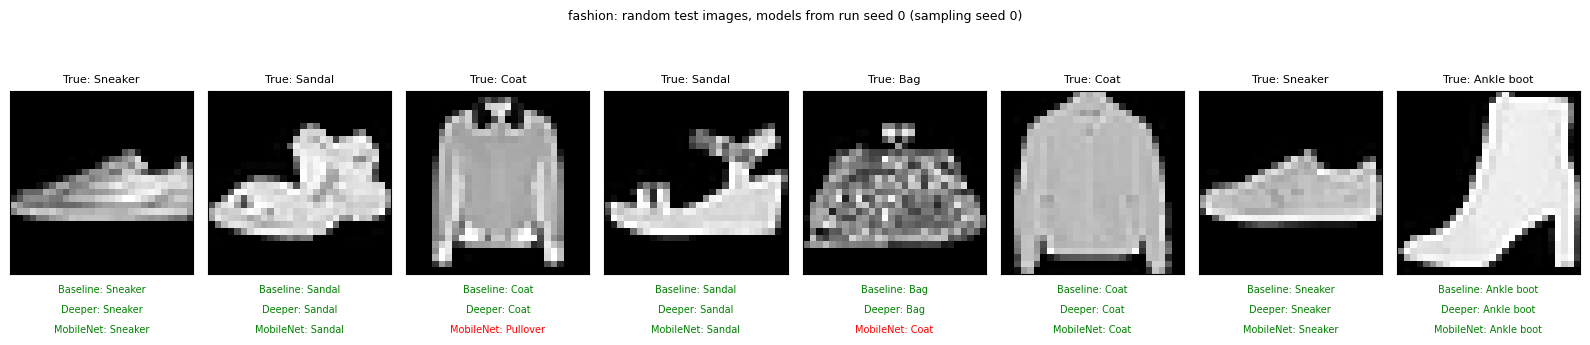

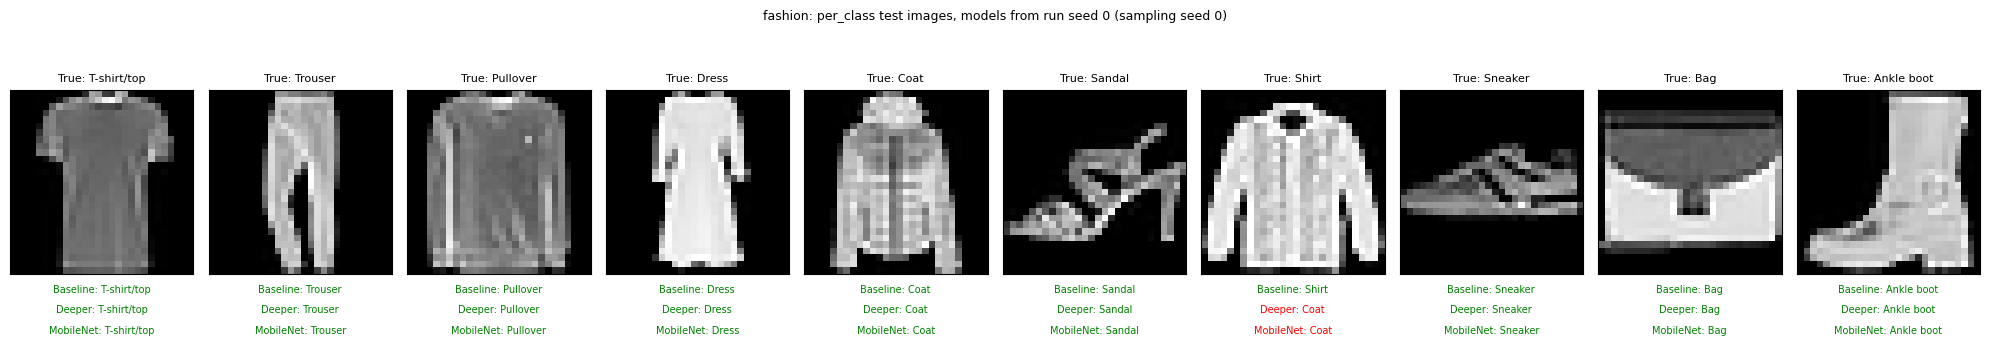

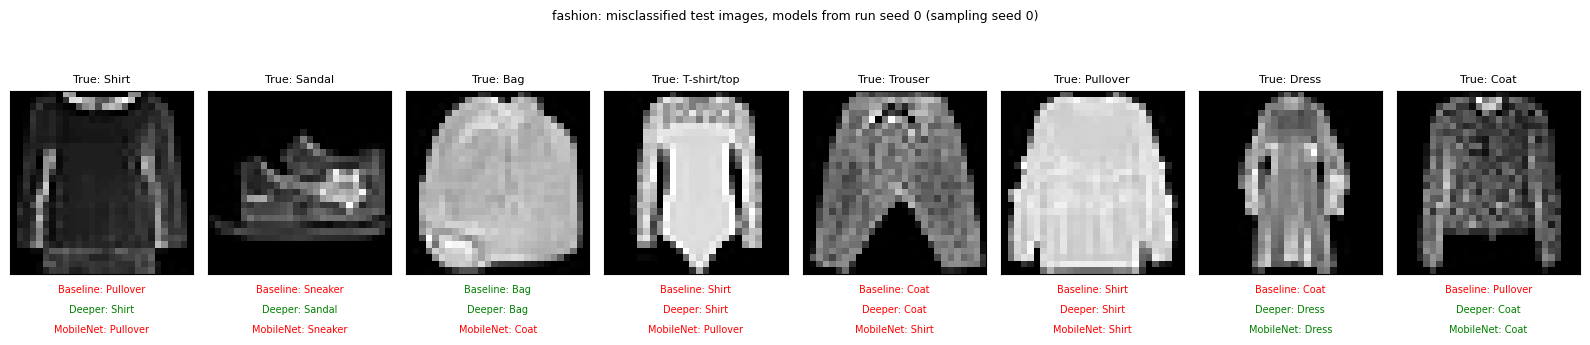

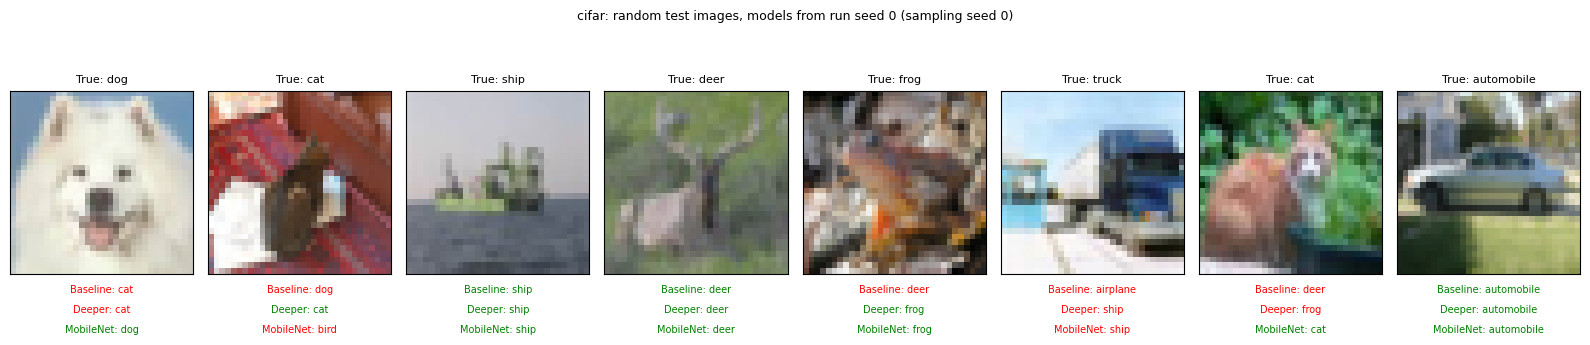

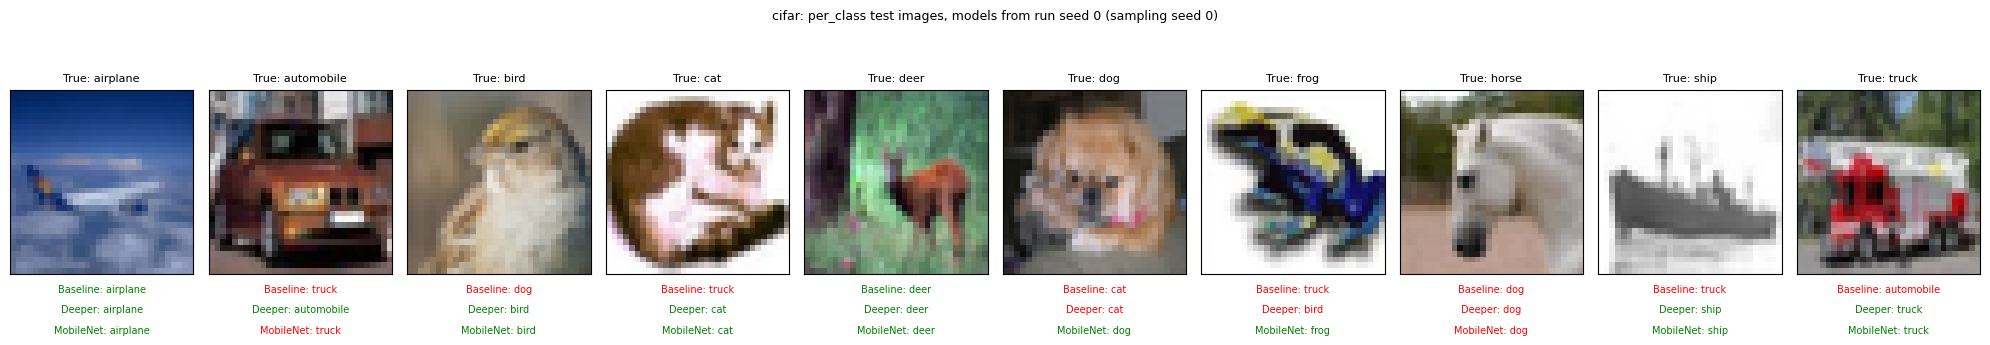

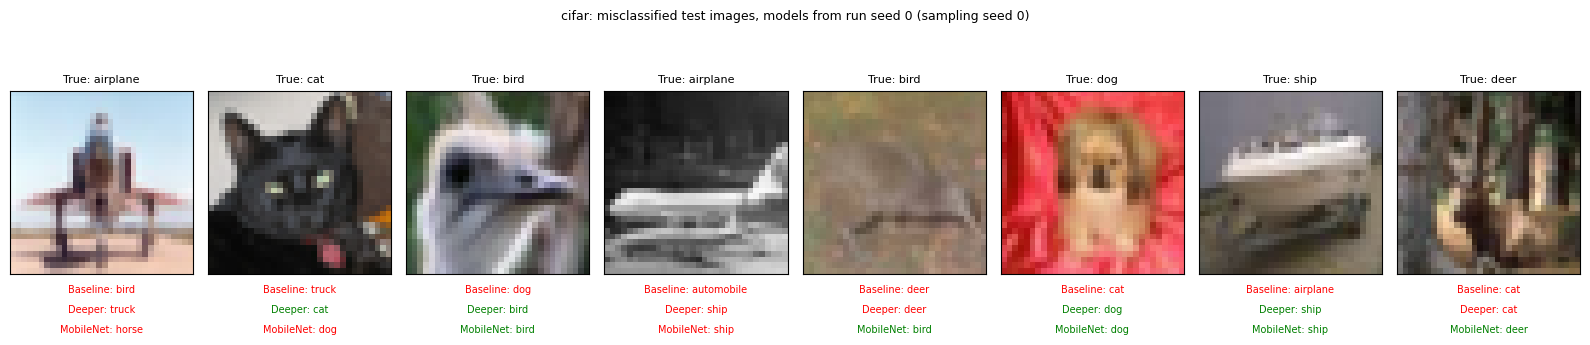

In [ ]:
SHORT = {'baseline': 'Baseline', 'deeper': 'Deeper', 'mobilenet_frozen': 'MobileNet'}

def save_fig_preds(name):
    plt.savefig(f'{PRED_DIR}/{name}.png', dpi=300, bbox_inches='tight')

def to_show_preds(t):
    return t.clamp(0, 1).permute(1, 2, 0).squeeze().numpy()

def predictions_figure(raw, ds, classes, models=('baseline', 'deeper', 'mobilenet_frozen'),
                       run_seed=0, n=8, pick='random', seed=0):
    """pick: 'random' | 'per_class' | 'misclassified'"""
    P = {m: np.load(f'{LOG_DIR}/preds_{ds}_{m}_seed{run_seed}.npy') for m in models}
    y = raw['y_te'].numpy()
    rs = np.random.RandomState(seed)

    if pick == 'random':
        idxs = rs.choice(len(y), n, replace=False)
    elif pick == 'per_class':
        idxs = np.array([rs.choice(np.where(y == c)[0]) for c in range(len(classes))])
    elif pick == 'misclassified':
        wrong = np.where(np.any([P[m] != y for m in models], axis=0))[0]
        idxs = rs.choice(wrong, min(n, len(wrong)), replace=False)
    else:
        raise ValueError(pick)

    cols = len(idxs)
    fig, ax = plt.subplots(1, cols, figsize=(2.0 * cols, 3.3), squeeze=False)
    for c, i in enumerate(idxs):
        a = ax[0, c]
        a.imshow(to_show_preds(raw['X_te'][i]), cmap='gray')
        a.set_xticks([]); a.set_yticks([])
        a.set_title(f'True: {classes[y[i]]}', fontsize=8)
        for k, m in enumerate(models):
            ok = P[m][i] == y[i]
            a.text(0.5, -0.06 - 0.11 * k, f'{SHORT.get(m, m)}: {classes[P[m][i]]}',
                   transform=a.transAxes, ha='center', va='top', fontsize=7,
                   color='green' if ok else 'red')
    fig.suptitle(f'{ds}: {pick} test images, models from run seed {run_seed} (sampling seed {seed})',
                 fontsize=9)
    plt.tight_layout()
    save_fig_preds(f'fig_predictions_{ds}_{pick}')
    plt.show()

fashion_raw = load_data('fashion')
predictions_figure(fashion_raw, 'fashion', FASHION_CLASSES, pick='random', n=8)
predictions_figure(fashion_raw, 'fashion', FASHION_CLASSES, pick='per_class')
predictions_figure(fashion_raw, 'fashion', FASHION_CLASSES, pick='misclassified', n=8)

cifar_raw = load_data('cifar')
predictions_figure(cifar_raw, 'cifar', CIFAR_CLASSES, pick='random', n=8)
predictions_figure(cifar_raw, 'cifar', CIFAR_CLASSES, pick='per_class')
predictions_figure(cifar_raw, 'cifar', CIFAR_CLASSES, pick='misclassified', n=8)

In [ ]:
res = pd.read_csv(RESULTS)
cur = pd.read_csv(CURVES).rename(columns={'vald_loss': 'val_loss'})

#Kernel size and stride ablation
Mean test accuracy and training time for each kernel/stride combination (Fashion-MNIST, baseline CNN).

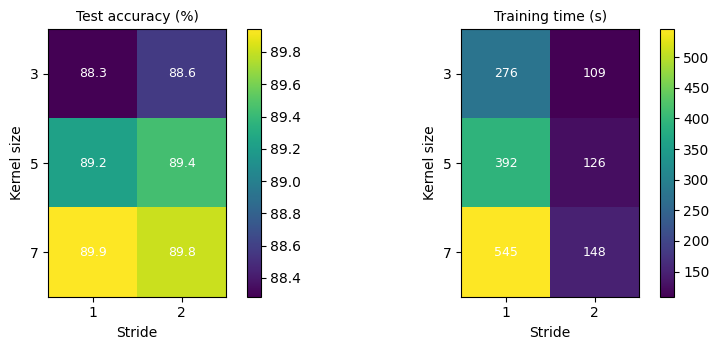

In [ ]:
def save_fig_abs(name):
  plt.savefig(f'{GRAPHS_DIR}/{name}.png', dpi=300, bbox_inches='tight')

def ablation_figure():
    df = res[(res.dataset == 'fashion') & res.model.str.startswith('baseline')].copy()
    def ks(m):
        if m == 'baseline': return 3, 1
        _, k, s = m.split('_'); return int(k[1:]), int(s[1:])
    df[['k', 's']] = df.model.apply(lambda m: pd.Series(ks(m)))
    g = df.groupby(['k', 's']).agg(acc=('test_acc', 'mean'), t=('train_time_s', 'mean')).reset_index()
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    for ax, col, title, fmt, mult in zip(axes, ['acc', 't'],
                                         ['Test accuracy (%)', 'Training time (s)'],
                                         ['{:.1f}', '{:.0f}'], [100, 1]):
        M = g.pivot(index='k', columns='s', values=col) * mult
        im = ax.imshow(M.values, cmap='viridis')
        ax.set_xticks(range(len(M.columns))); ax.set_xticklabels(M.columns)
        ax.set_yticks(range(len(M.index))); ax.set_yticklabels(M.index)
        ax.set_xlabel('Stride'); ax.set_ylabel('Kernel size'); ax.set_title(title, fontsize=10)
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                ax.text(j, i, fmt.format(M.values[i, j]), ha='center', va='center',
                        color='white', fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); save_fig_abs('fig_ablation_fashion'); plt.show()

ablation_figure()

#Confusion matrices
Row-normalised, pooled over seeds. Each row shows how the images of one true class were classified.


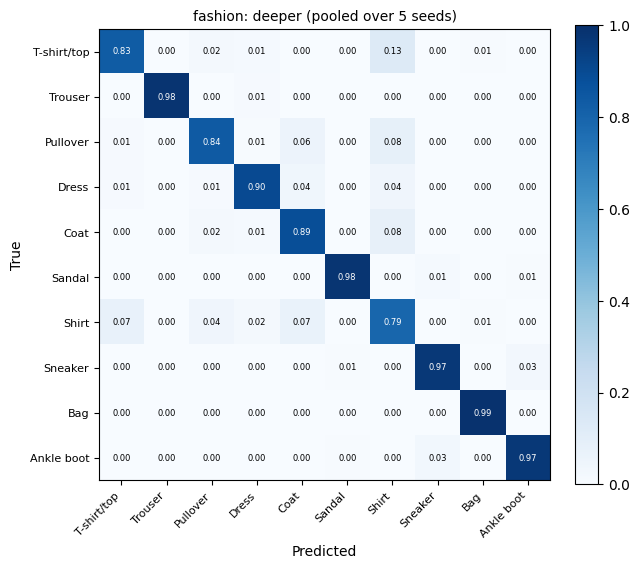

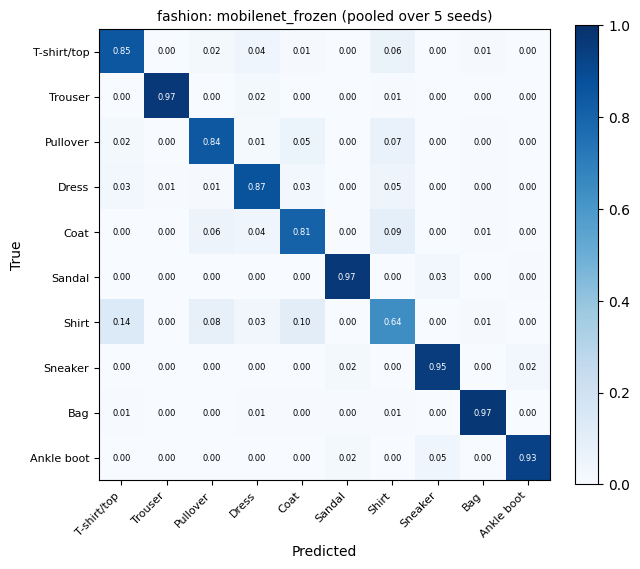

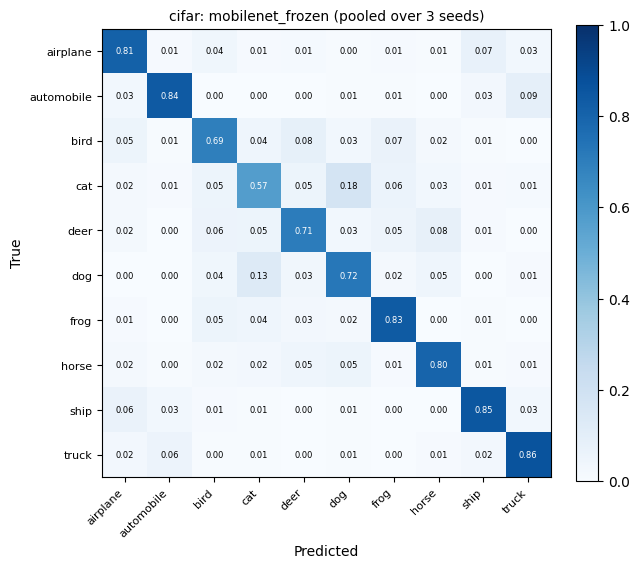

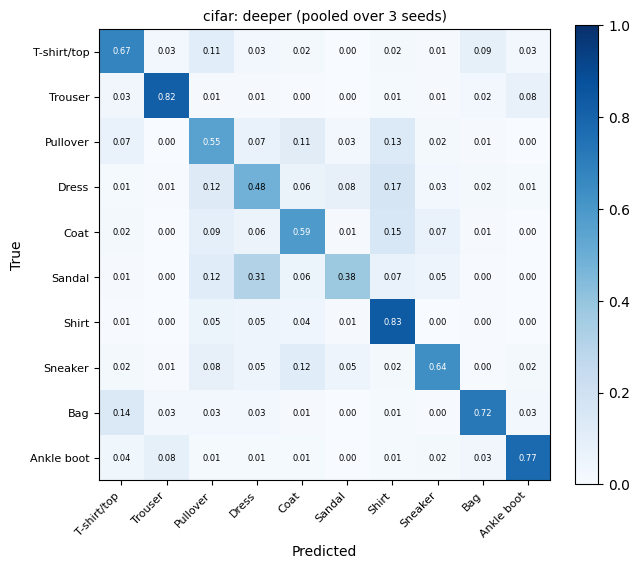

In [ ]:
def confusion_figure(ds, model, classes):
    files = sorted(glob.glob(f'{LOG_DIR}/cm_{ds}_{model}_seed*.npy'))
    cm = sum(np.load(f) for f in files).astype(float)
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(6.5, 6))
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(10)); ax.set_xticklabels(classes, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(10)); ax.set_yticklabels(classes, fontsize=8)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, f'{cmn[i, j]:.2f}', ha='center', va='center', fontsize=6,
                    color='white' if cmn[i, j] > 0.5 else 'black')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'{ds}: {model} (pooled over {len(files)} seeds)', fontsize=10)
    fig.colorbar(im, fraction=0.046)
    plt.tight_layout(); save_fig(f'fig_confusion_{ds}_{model}'); plt.show()

confusion_figure('fashion', 'deeper', FASHION_CLASSES)
confusion_figure('fashion', 'mobilenet_frozen', FASHION_CLASSES)
confusion_figure('cifar', 'mobilenet_frozen', CIFAR_CLASSES)
confusion_figure('cifar', 'deeper', FASHION_CLASSES)

#Training and validation curves
Mean over seeds with a band of +/-1 standard deviation. Training loss is a running average with dropout active, so it is not directly comparable with validation loss.

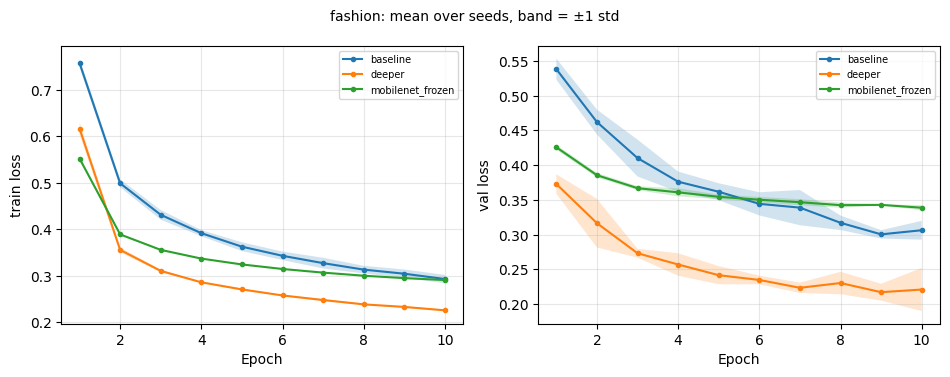

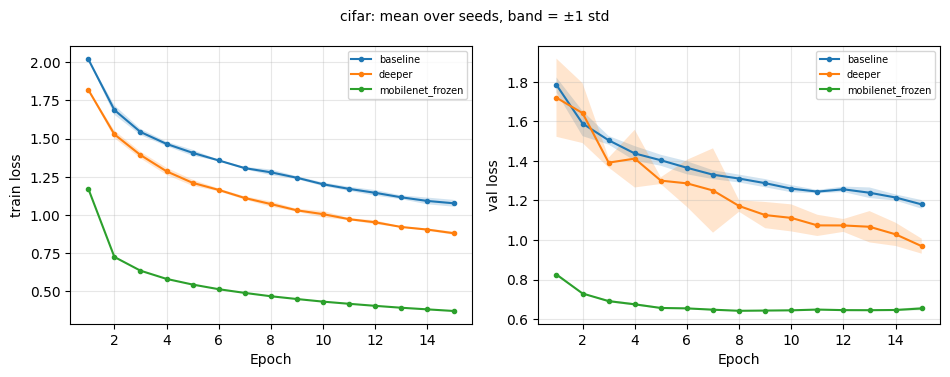

In [ ]:
def save_fig_curves(name):
  plt.savefig(f'{GRAPHS_DIR}/{name}.png', dpi=300, bbox_inches='tight')

def plot_curves(ds, models=MAIN, metrics=('train_loss', 'val_loss')):
    df = cur[cur.dataset == ds]
    fig, axes = plt.subplots(1, len(metrics), figsize=(4.8 * len(metrics), 3.8))
    for ax, met in zip(np.atleast_1d(axes), metrics):
        for m in models:
            g = df[df.model == m].groupby('epoch')[met].agg(['mean', 'std']).fillna(0)
            ax.plot(g.index, g['mean'], marker='o', ms=3, label=m)
            ax.fill_between(g.index, g['mean'] - g['std'], g['mean'] + g['std'], alpha=0.2)
        ax.set_xlabel('Epoch'); ax.set_ylabel(met.replace('_', ' '))
        ax.grid(alpha=0.3); ax.legend(fontsize=7)
    fig.suptitle(f'{ds}: mean over seeds, band = ±1 std', fontsize=10)
    plt.tight_layout(); save_fig_curves(f'fig_curves_{ds}'); plt.show()

plot_curves('fashion'); plot_curves('cifar')

#Accuracy versus training time
Accuracy against cost for each model (mean +/- std over seeds, log time axis). MobileNet time includes feature extraction.

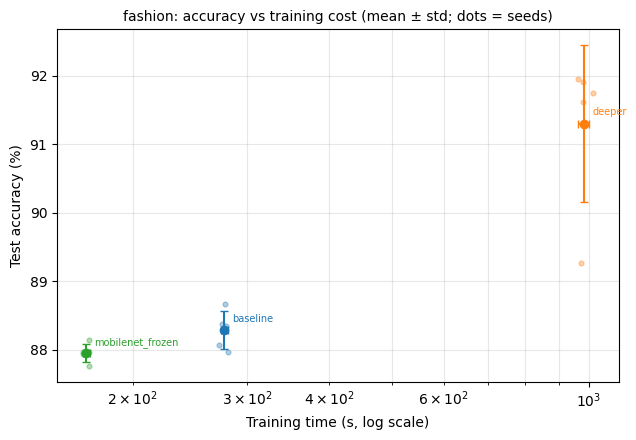

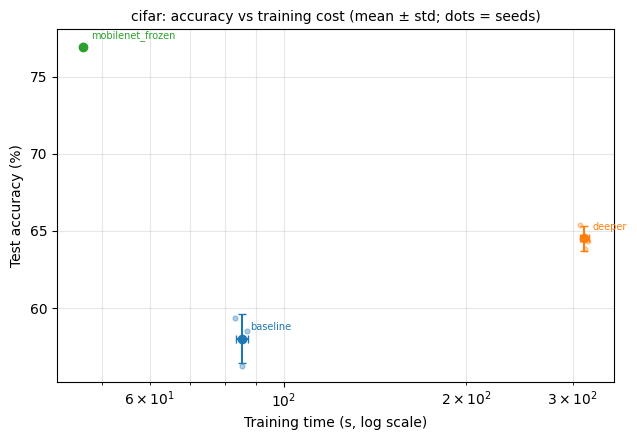

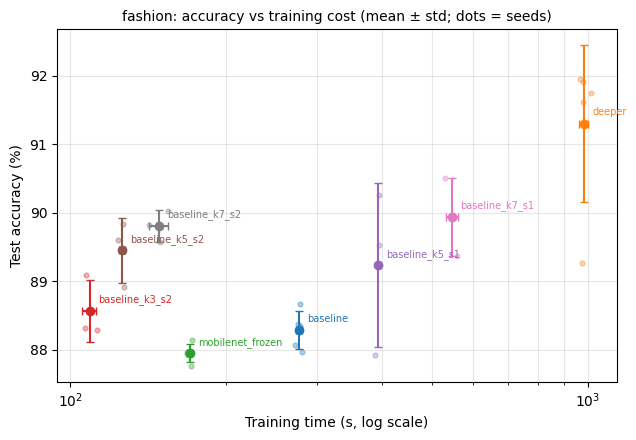

In [ ]:
def acc_vs_time(ds, models=MAIN, show_seeds=True, annotate=True, suffix=''):
    df = res[res.dataset == ds]
    g = (df.groupby('model')
         .agg(acc=('test_acc', 'mean'), acc_sd=('test_acc', 'std'),
              t=('train_time_s', 'mean'), t_sd=('train_time_s', 'std')).fillna(0))
    models = [m for m in models if m in g.index]
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    colors = plt.cm.tab10(np.linspace(0, 1, 10))
    for k, m in enumerate(models):
        c = colors[k % 10]
        if show_seeds:   # individual seeds
            s = df[df.model == m]
            ax.scatter(s.train_time_s, s.test_acc * 100, s=12, color=c, alpha=0.35)
        r = g.loc[m]    # mean ± std
        ax.errorbar(r.t, r.acc * 100, xerr=r.t_sd, yerr=r.acc_sd * 100,
                    fmt='o', color=c, capsize=3, ms=6, label=m)
        if annotate:
            ax.annotate(m, (r.t, r.acc * 100), textcoords='offset points',
                        xytext=(6, 6), fontsize=7, color=c)
    ax.set_xscale('log'); ax.grid(alpha=0.3, which='both')
    ax.set_xlabel('Training time (s, log scale)')
    ax.set_ylabel('Test accuracy (%)')
    ax.set_title(f'{ds}: accuracy vs training cost (mean ± std; dots = seeds)', fontsize=10)
    plt.tight_layout()
    save_fig(f'fig_acc_vs_time_{ds}{suffix}')
    plt.show()

# main models, both datasets
acc_vs_time('fashion')
acc_vs_time('cifar')

# Fashion-MNIST with the kernel/stride ablation configurations included
abl = [m for m in res.model.unique() if m.startswith('baseline')]
acc_vs_time('fashion', models=MAIN + [m for m in abl if m not in MAIN],
            suffix='_with_ablation')

In [ ]:
summary = (res.groupby(['dataset', 'model'])
           .agg(acc_mean=('test_acc', 'mean'), acc_std=('test_acc', 'std'),
                time_mean=('train_time_s', 'mean'), time_std=('train_time_s', 'std'),
                params=('params', 'first'), n_seeds=('seed', 'count')).round(4))
summary.to_csv(f'{FIG_DIR}/summary_table.csv')
summary

acc_mean  acc_std  time_mean  time_std  params  \
dataset model                                                              
cifar   baseline            0.5803   0.0160    85.1789    1.9085   38570   
        deeper              0.6453   0.0081   313.8897    5.0582   73178   
        mobilenet_frozen    0.7693   0.0008    46.4795    0.0491   10250   
fashion baseline            0.8828   0.0028   276.3930    3.3165   38282   
        baseline_k3_s2      0.8857   0.0045   108.8514    3.3625   38282   
        baseline_k5_s1      0.8923   0.0119   392.4625    3.7598   46730   
        baseline_k5_s2      0.8945   0.0048   125.6064    1.6794   46730   
        baseline_k7_s1      0.8994   0.0057   545.3652   14.7045   59402   
        baseline_k7_s2      0.8981   0.0023   148.1951    6.2810   59402   
        deeper              0.9130   0.0114   982.3779   19.6342   72890   
        mobilenet_frozen    0.8795   0.0013   169.8875    2.0047   10250   

                          n_seeds  
dataset model                      
cifar   baseline                3  
        deeper                  3  
        mobilenet_frozen        3  
fashion baseline                5  
        baseline_k3_s2          3  
        baseline_k5_s1          3  
        baseline_k5_s2          3  
        baseline_k7_s1          3  
        baseline_k7_s2          3  
        deeper                  5  
        mobilenet_frozen        5

In [ ]:
# 1. stability: coefficient of variation (%) of test accuracy
cv = res.groupby(['dataset', 'model']).test_acc.agg(lambda s: s.std() / s.mean() * 100)
print(cv.round(2))

# 2. timing vs run order (seed index)
for (ds, m), g in res.groupby(['dataset', 'model']):
    if len(g) >= 3:
        print(ds, m, 'corr(seed, time) =', round(np.corrcoef(g.seed, g.train_time_s)[0, 1], 2))

# 3. epoch-1 validation accuracy vs final test accuracy
e1 = cur[cur.epoch == 1].set_index(['dataset', 'model', 'seed']).val_acc.rename('val_ep1')
fin = res.set_index(['dataset', 'model', 'seed']).test_acc
j = pd.concat([e1, fin], axis=1).dropna()
print(j.groupby(['dataset', 'model']).apply(lambda g: g.val_ep1.corr(g.test_acc)).round(2))

dataset  model           
cifar    baseline            2.76
         deeper              1.25
         mobilenet_frozen    0.11
fashion  baseline            0.31
         baseline_k3_s2      0.51
         baseline_k5_s1      1.34
         baseline_k5_s2      0.54
         baseline_k7_s1      0.63
         baseline_k7_s2      0.26
         deeper              1.25
         mobilenet_frozen    0.15
Name: test_acc, dtype: float64
cifar baseline corr(seed, time) = -1.0
cifar deeper corr(seed, time) = 0.38
cifar mobilenet_frozen corr(seed, time) = -0.97
fashion baseline corr(seed, time) = -0.13
fashion baseline_k3_s2 corr(seed, time) = -0.85
fashion baseline_k5_s1 corr(seed, time) = 0.22
fashion baseline_k5_s2 corr(seed, time) = -0.7
fashion baseline_k7_s1 corr(seed, time) = -0.38
fashion baseline_k7_s2 corr(seed, time) = -0.57
fashion deeper corr(seed, time) = -0.63
fashion mobilenet_frozen corr(seed, time) = -0.02
dataset  model           
cifar    baseline            0.09
         deeper